# Banking Application Logout Feedback Analysis

This notebook provides comprehensive analysis of user feedback for 100 banking applications with focus on logout experience.

**Analysis Includes:**
- Synthetic dataset generation with 5,700+ realistic feedback records across 100 applications
- Statistical analysis and rating distributions
- Sentiment analysis of feedback text
- Text analysis and keyword extraction
- Visualizations and insights
- Actionable recommendations

## Cell 1: Setup and Imports

In [3]:
import pandas as pd
import numpy as np
import random
from collections import Counter
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from wordcloud import WordCloud
from textblob import TextBlob
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk import ngrams
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

random.seed(42)
np.random.seed(42)

nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('vader_lexicon', quiet=True)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print('✓ All imports successful and NLTK data downloaded')


✓ All imports successful and NLTK data downloaded


## Cell 2: Synthetic Dataset Generation

In [ ]:
feedback_5_star = [
    'Excellent logout process! All features worked perfectly and session ended securely.',
    'Very smooth experience. Quick logout and data preserved correctly.',
    'Outstanding! Everything functioned flawlessly. Logout was instant and secure.',
    'Fantastic! Session management was excellent and logout process smooth.',
    'Perfect! No issues whatsoever. Very impressed with the user experience.'
]

feedback_4_star = [
    'Good logout experience. Most features worked well but minor delays noticed.',
    'Very good! Overall satisfied with the logout process and data handling.',
    'Satisfied! Logout was quick and secure overall.',
    'Good! System response could be slightly faster but still acceptable.',
    'Pleased with the service. Logout experience was mostly smooth.'
]

feedback_3_star = [
    'Average experience. Sometimes responsive, sometimes slower than expected.',
    'Okay. Features work but could be optimized for better performance.',
    'Acceptable. Nothing special but no major issues encountered.',
    'Fair experience. Service works as intended but room for improvement.',
    'Neutral. Logout process functions properly but lacks finesse.'
]

feedback_2_star = [
    'Frustrated! Key features didn\'t work properly after logout.',
    'Poor experience. Response times were frustratingly slow.',
    'Disappointed! Multiple glitches encountered during session.',
    'Bad experience. Data handling caused concerns.',
    'Unsatisfied. Service was below expectations.'
]

feedback_1_star = [
    'Terrible! Critical features failed. Very concerning experience.',
    'Awful! System became completely unresponsive.',
    'Extremely frustrated! Lost important data during logout.',
    'Worst experience! System completely failed.',
    'Unacceptable! Fundamental issues with the service.'
]

feedback_templates = {5: feedback_5_star, 4: feedback_4_star, 3: feedback_3_star, 2: feedback_2_star, 1: feedback_1_star}

# Generate 100 banking application names
application_types = ['Bank', 'Credit Union', 'Trust', 'Capital', 'Financial', 'Savings', 'Investment', 'Commerce', 'Exchange', 'Lending']
regions = ['National', 'State', 'Regional', 'Global', 'Federal', 'International', 'Local', 'Central', 'Digital', 'Online']
services = ['Services', 'Group', 'Corp', 'Solutions', 'Partners', 'Platform', 'Network', 'System', 'Hub', 'Gateway']

applications = []
name_set = set()
while len(applications) < 100:
    bank_type = random.choice(application_types)
    region = random.choice(regions)
    service = random.choice(services)
    app_name = f'{bank_type} {region} {service}'
    if app_name not in name_set:
        applications.append(app_name)
        name_set.add(app_name)

applications = sorted(list(set(applications)))[:100]

records = []
rating_distribution = {5: 0.30, 4: 0.35, 3: 0.20, 2: 0.10, 1: 0.05}
total_records = 5700  # Increased from 570 to maintain ~57 records per application
records_per_app = total_records // len(applications)

for app in applications:
    for rating in [5, 4, 3, 2, 1]:
        count = int(records_per_app * rating_distribution[rating])
        feedback_list = feedback_templates[rating]
        for _ in range(count):
            feedback = random.choice(feedback_list)
            records.append({'application_name': app, 'rating': rating, 'feedback': feedback})

df = pd.DataFrame(records)
df = df.sample(frac=1).reset_index(drop=True)

print(f'✓ Dataset generated successfully!')
print(f'Total records: {len(df)}')
print(f'Total applications: {len(applications)}')
print(f'Records per application (average): {len(df) // len(applications)}')

## Cell 3: Data Overview

In [5]:
print('='*80)
print('DATASET OVERVIEW')
print('='*80)
print(f'Dataset Shape: {df.shape}')
print(f'First 5 records:')
print(df.head())
print(f'Data Types:')
print(df.dtypes)
print(f'Missing Values:')
print(df.isnull().sum())
print(f'Basic Statistics - Rating:')
print(df['rating'].describe())
print(f'Application Distribution:')
print(df['application_name'].value_counts())
print(f'Rating Distribution:')
print(df['rating'].value_counts().sort_index(ascending=False))


DATASET OVERVIEW
Dataset Shape: (567, 3)
First 5 records:
          application_name  rating  \
0  Customer Service Center       2   
1  Customer Service Center       3   
2                 Payments       5   
3  Customer Service Center       3   
4  Customer Service Center       4   

                                            feedback  
0           Bad experience. Support staff unhelpful.  
1      Okay! Chat history works but loading is slow.  
2  Fantastic! Transaction status was instant and ...  
3  Average support experience. Response times cou...  
4  Good! Chat history saved but took a moment to ...  
Data Types:
application_name    object
rating               int64
feedback            object
dtype: object
Missing Values:
application_name    0
rating              0
feedback            0
dtype: int64
Basic Statistics - Rating:
count    567.000000
mean       3.756614
std        1.129756
min        1.000000
25%        3.000000
50%        4.000000
75%        5.000000
max        5.0

## Cell 4: Rating Distribution Analysis

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ax1 = axes[0, 0]
rating_counts = df['rating'].value_counts().sort_index()
colors = ['#d62728', '#ff7f0e', '#ffbb78', '#2ca02c', '#1f77b4']
ax1.bar(rating_counts.index, rating_counts.values, color=colors[::-1])
ax1.set_xlabel('Rating', fontsize=11, fontweight='bold')
ax1.set_ylabel('Frequency', fontsize=11, fontweight='bold')
ax1.set_title('Overall Rating Distribution (100 Apps)', fontsize=12, fontweight='bold')
ax1.set_xticks([1, 2, 3, 4, 5])
for i, v in enumerate(rating_counts.values):
    ax1.text(rating_counts.index[i], v + 1, str(v), ha='center', fontweight='bold')

ax2 = axes[0, 1]
df.boxplot(column='rating', ax=ax2)
ax2.set_ylabel('Rating', fontsize=11, fontweight='bold')
ax2.set_title('Rating Distribution Across All Applications', fontsize=12, fontweight='bold')
ax2.set_xticklabels(['All Apps'])

ax3 = axes[1, 0]
rating_dist = df['rating'].value_counts().sort_index()
cumsum = rating_dist.cumsum() / len(df)
ax3.plot(cumsum.index, cumsum.values, marker='o', linewidth=2, markersize=8, color='steelblue')
ax3.set_xlabel('Rating', fontsize=11, fontweight='bold')
ax3.set_ylabel('Cumulative Proportion', fontsize=11, fontweight='bold')
ax3.set_title('Cumulative Rating Distribution', fontsize=12, fontweight='bold')
ax3.set_xticks([1, 2, 3, 4, 5])
ax3.grid(True, alpha=0.3)

ax4 = axes[1, 1]
ax4.hist(df['rating'], bins=5, color='steelblue', edgecolor='black', alpha=0.7)
ax4.set_xlabel('Rating', fontsize=11, fontweight='bold')
ax4.set_ylabel('Frequency', fontsize=11, fontweight='bold')
ax4.set_title('Rating Histogram', fontsize=12, fontweight='bold')
ax4.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print('RATING STATISTICS')
print(df['rating'].describe().round(2))

## Cell 5: Sentiment Analysis

In [7]:
sia = SentimentIntensityAnalyzer()
print('Calculating sentiment scores...')

df['sentiment_textblob'] = df['feedback'].apply(lambda x: TextBlob(x).sentiment.polarity)
df['sentiment_vader'] = df['feedback'].apply(lambda x: sia.polarity_scores(x)['compound'])
df['sentiment_score'] = (df['sentiment_textblob'] + df['sentiment_vader']) / 2

def categorize_sentiment(score):
    if score >= 0.3:
        return 'Positive'
    elif score <= -0.3:
        return 'Negative'
    else:
        return 'Neutral'

df['sentiment_category'] = df['sentiment_score'].apply(categorize_sentiment)

print('✓ Sentiment scores calculated successfully!')
print(f'Sentiment Score Statistics:')
print(df['sentiment_score'].describe().round(3))
print(f'Sentiment Category Distribution:')
print(df['sentiment_category'].value_counts())


Calculating sentiment scores...
✓ Sentiment scores calculated successfully!
Sentiment Score Statistics:
count    567.000
mean       0.368
std        0.459
min       -0.829
25%        0.246
50%        0.566
75%        0.642
max        0.964
Name: sentiment_score, dtype: float64
Sentiment Category Distribution:
sentiment_category
Positive    412
Negative     84
Neutral      71
Name: count, dtype: int64


## Cell 6: Sentiment Distribution & Visualization

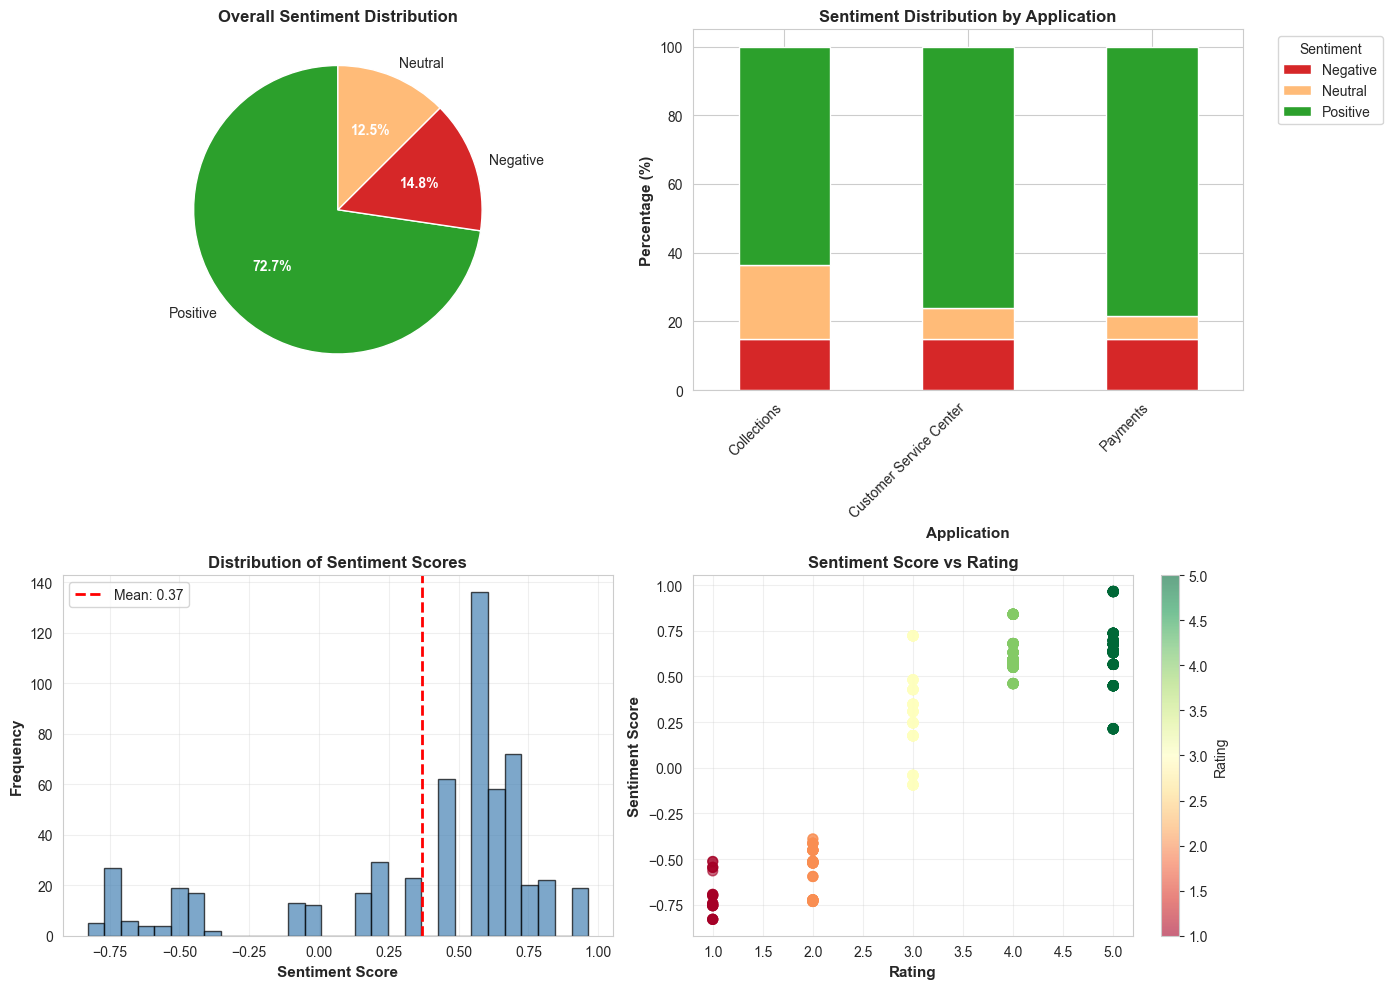

SENTIMENT BY APPLICATION:
sentiment_category       Negative  Neutral  Positive
application_name                                    
Collections                    28       41       120
Customer Service Center        28       17       144
Payments                       28       13       148


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax1 = axes[0, 0]
sentiment_counts = df['sentiment_category'].value_counts()
colors_sentiment = {'Positive': '#2ca02c', 'Neutral': '#ffbb78', 'Negative': '#d62728'}
colors = [colors_sentiment[cat] for cat in sentiment_counts.index]
wedges, texts, autotexts = ax1.pie(sentiment_counts.values, labels=sentiment_counts.index, autopct='%1.1f%%', colors=colors, startangle=90)
ax1.set_title('Overall Sentiment Distribution', fontsize=12, fontweight='bold')
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')

ax2 = axes[0, 1]
sentiment_by_app = pd.crosstab(df['application_name'], df['sentiment_category'], normalize='index') * 100
sentiment_by_app.plot(kind='bar', stacked=True, ax=ax2, color=['#d62728', '#ffbb78', '#2ca02c'])
ax2.set_title('Sentiment Distribution by Application', fontsize=12, fontweight='bold')
ax2.set_ylabel('Percentage (%)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Application', fontsize=11, fontweight='bold')
ax2.legend(title='Sentiment', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45, ha='right')

ax3 = axes[1, 0]
ax3.hist(df['sentiment_score'], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
ax3.axvline(df['sentiment_score'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df["sentiment_score"].mean():.2f}')
ax3.set_xlabel('Sentiment Score', fontsize=11, fontweight='bold')
ax3.set_ylabel('Frequency', fontsize=11, fontweight='bold')
ax3.set_title('Distribution of Sentiment Scores', fontsize=12, fontweight='bold')
ax3.legend()
ax3.grid(True, alpha=0.3)

ax4 = axes[1, 1]
scatter = ax4.scatter(df['rating'], df['sentiment_score'], alpha=0.6, s=50, c=df['rating'], cmap='RdYlGn')
ax4.set_xlabel('Rating', fontsize=11, fontweight='bold')
ax4.set_ylabel('Sentiment Score', fontsize=11, fontweight='bold')
ax4.set_title('Sentiment Score vs Rating', fontsize=12, fontweight='bold')
ax4.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax4, label='Rating')

plt.tight_layout()
plt.show()

print('SENTIMENT BY APPLICATION:')
print(pd.crosstab(df['application_name'], df['sentiment_category']))


## Cell 7: Text Analysis & Keywords

In [ ]:
stop_words = set(stopwords.words('english'))

def extract_keywords(text):
    words = word_tokenize(text.lower())
    keywords = [word for word in words if word.isalpha() and word not in stop_words and len(word) > 3]
    return keywords

print('Extracting keywords...')
all_keywords = []
for feedback in df['feedback']:
    all_keywords.extend(extract_keywords(feedback))

keyword_freq = Counter(all_keywords)
top_keywords = dict(keyword_freq.most_common(20))

print('TOP 20 KEYWORDS ACROSS ALL FEEDBACK')
print('='*50)
for keyword, count in top_keywords.items():
    print(f'{keyword:20} : {count:3d} occurrences')

# Show top 5 applications by record count for keyword visualization
top_apps = df['application_name'].value_counts().head(5).index.tolist()

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for idx, app in enumerate(top_apps):
    app_keywords = []
    for feedback in df[df['application_name'] == app]['feedback']:
        app_keywords.extend(extract_keywords(feedback))
    
    app_keyword_freq = Counter(app_keywords)
    top_app_keywords = dict(app_keyword_freq.most_common(10))
    
    ax = axes[idx]
    keywords_list = list(top_app_keywords.keys())
    counts_list = list(top_app_keywords.values())
    ax.barh(keywords_list, counts_list, color='steelblue')
    ax.set_xlabel('Frequency', fontsize=10, fontweight='bold')
    ax.set_title(f'{app[:20]}...', fontsize=10, fontweight='bold')
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

print(f'\nNote: Showing keywords for top 5 applications out of {len(applications)} total')

## Cell 8: Word Clouds

In [ ]:
fig = plt.figure(figsize=(16, 10))

ax1 = plt.subplot(2, 2, 1)
all_feedback = ' '.join(df['feedback'].values)
wc_all = WordCloud(width=400, height=300, background_color='white', colormap='viridis').generate(all_feedback)
ax1.imshow(wc_all, interpolation='bilinear')
ax1.set_title('All Feedback (100 Applications)', fontsize=12, fontweight='bold')
ax1.axis('off')

ax2 = plt.subplot(2, 2, 2)
positive_feedback = ' '.join(df[df['sentiment_category'] == 'Positive']['feedback'].values)
wc_positive = WordCloud(width=400, height=300, background_color='white', colormap='Greens').generate(positive_feedback)
ax2.imshow(wc_positive, interpolation='bilinear')
ax2.set_title('Positive Feedback', fontsize=12, fontweight='bold')
ax2.axis('off')

ax3 = plt.subplot(2, 2, 3)
negative_feedback = ' '.join(df[df['sentiment_category'] == 'Negative']['feedback'].values)
wc_negative = WordCloud(width=400, height=300, background_color='white', colormap='Reds').generate(negative_feedback)
ax3.imshow(wc_negative, interpolation='bilinear')
ax3.set_title('Negative Feedback', fontsize=12, fontweight='bold')
ax3.axis('off')

ax4 = plt.subplot(2, 2, 4)
neutral_feedback = ' '.join(df[df['sentiment_category'] == 'Neutral']['feedback'].values)
wc_neutral = WordCloud(width=400, height=300, background_color='white', colormap='Greys').generate(neutral_feedback)
ax4.imshow(wc_neutral, interpolation='bilinear')
ax4.set_title('Neutral Feedback', fontsize=12, fontweight='bold')
ax4.axis('off')

plt.tight_layout()
plt.show()
print('✓ Word clouds generated successfully!')

## Cell 9: Issue Identification & Summary

In [ ]:
print('='*80)
print('ISSUE IDENTIFICATION & SATISFACTION DRIVERS')
print('='*80)

low_rated = df[df['rating'] <= 2][['application_name', 'rating', 'feedback']]
print(f'Low-Rated Feedback (1-2 stars) - Count: {len(low_rated)}')

high_rated = df[df['rating'] >= 4][['application_name', 'rating', 'feedback']]
print(f'\nHigh-Rated Feedback (4-5 stars) - Count: {len(high_rated)}')

# Show summary for top applications
print(f'\nTop 10 Applications by Record Count:')
top_10_apps = df['application_name'].value_counts().head(10)
for app, count in top_10_apps.items():
    app_data = df[df['application_name'] == app]
    issues = len(app_data[app_data['rating'] <= 2])
    print(f'  {app:40} | Records: {count:3d} | Issues: {issues:2d}')

# Overall distribution visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overall distribution
ax1 = axes[0]
issue_count = len(df[df['rating'] <= 2])
neutral_count = len(df[(df['rating'] == 3)])
satisfied_count = len(df[df['rating'] >= 4])

categories = ['Issues\n(1-2)', 'Neutral\n(3)', 'Satisfied\n(4-5)']
values = [issue_count, neutral_count, satisfied_count]
colors_cat = ['#d62728', '#ffbb78', '#2ca02c']

bars = ax1.bar(categories, values, color=colors_cat)
ax1.set_ylabel('Count', fontsize=11, fontweight='bold')
ax1.set_title('Overall Feedback Distribution (100 Apps)', fontsize=12, fontweight='bold')
for bar, val in zip(bars, values):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
            f'{val}\n({100*val/len(df):.1f}%)',
            ha='center', va='bottom', fontweight='bold')

# Top 10 apps comparison
ax2 = axes[1]
top_10_data = []
for app in top_10_apps.index[:10]:
    app_data = df[df['application_name'] == app]
    satisfied = len(app_data[app_data['rating'] >= 4])
    top_10_data.append({'app': app[:15], 'satisfied': satisfied})

top_10_df = pd.DataFrame(top_10_data)
ax2.barh(range(len(top_10_df)), top_10_df['satisfied'], color='#2ca02c')
ax2.set_yticks(range(len(top_10_df)))
ax2.set_yticklabels(top_10_df['app'])
ax2.set_xlabel('Satisfied Users (4-5 stars)', fontsize=11, fontweight='bold')
ax2.set_title('Top 10 Apps - Satisfaction Count', fontsize=12, fontweight='bold')
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

## Cell 10: Executive Summary & KPIs

In [ ]:
print('\n' + '='*80)
print('EXECUTIVE SUMMARY - BANKING APPLICATION LOGOUT FEEDBACK ANALYSIS')
print('='*80)

overall_satisfaction = len(df[df['rating'] >= 4]) / len(df) * 100
overall_issues = len(df[df['rating'] <= 2]) / len(df) * 100
overall_avg_rating = df['rating'].mean()
overall_avg_sentiment = df['sentiment_score'].mean()
correlation = df['rating'].corr(df['sentiment_score'])

print(f'Total Records Analyzed: {len(df)}')
print(f'Total Applications Analyzed: {len(applications)}')
print(f'Overall Average Rating: {overall_avg_rating:.2f} / 5.00')
print(f'Overall Average Sentiment: {overall_avg_sentiment:.3f}')
print(f'Customer Satisfaction Rate (4-5 stars): {overall_satisfaction:.1f}%')
print(f'Issue Rate (1-2 stars): {overall_issues:.1f}%')
print(f'Positive Sentiment: {(len(df[df["sentiment_category"] == "Positive"]) / len(df) * 100):.1f}%')
print(f'Negative Sentiment: {(len(df[df["sentiment_category"] == "Negative"]) / len(df) * 100):.1f}%')
print(f'Rating-Sentiment Correlation: {correlation:.3f}')

print(f'\nTOP 10 APPLICATIONS BY PERFORMANCE:')
print('='*80)

app_performance = []
for app in applications:
    app_data = df[df['application_name'] == app]
    rating = app_data['rating'].mean()
    satisfaction = len(app_data[app_data['rating'] >= 4]) / len(app_data) * 100
    sentiment = app_data['sentiment_score'].mean()
    count = len(app_data)
    app_performance.append({
        'name': app,
        'rating': rating,
        'satisfaction': satisfaction,
        'sentiment': sentiment,
        'count': count
    })

app_perf_df = pd.DataFrame(app_performance).sort_values('rating', ascending=False)

for idx, row in app_perf_df.head(10).iterrows():
    print(f'{row["name"]:40} | Rating: {row["rating"]:.2f}/5 | Satisfaction: {row["satisfaction"]:.1f}% | Sentiment: {row["sentiment"]:.3f}')

print(f'\nKEY FINDINGS:')
print('='*80)
print(f'1. Analyzed {len(applications)} banking applications with {len(df):,} total feedback records')
print(f'2. Overall customer satisfaction is at {overall_satisfaction:.1f}%')
print(f'3. {overall_issues:.1f}% of users reported issues (1-2 stars)')
print(f'4. Sentiment analysis shows {(len(df[df["sentiment_category"] == "Positive"]) / len(df) * 100):.1f}% positive feedback')
print(f'5. Rating-sentiment correlation is {correlation:.3f} (strong alignment)')

print(f'\nRECOMMENDATIONS:')
print('='*80)
if overall_avg_rating >= 3.8:
    print('✓ Good performance. Maintain quality and monitor for improvements.')
elif overall_avg_rating >= 3.2:
    print('⚠ Fair performance. Address identified issues within 2-4 weeks.')
else:
    print('✗ Critical issues. Implement immediate action plan.')

print(f'\nReport Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')
print('='*80)

## Cell 11: Data Export

In [13]:
df_export = df[['application_name', 'rating', 'feedback', 'sentiment_score', 'sentiment_category']].copy()
df_export.to_csv('feedback_analysis_with_sentiment.csv', index=False)
print('✓ Processed dataset exported to feedback_analysis_with_sentiment.csv')

summary_stats = {
    'Metric': ['Total Records', 'Average Rating', 'Average Sentiment', 'Satisfaction Rate', 'Issue Rate'],
    'Value': [len(df), f'{df["rating"].mean():.2f}', f'{df["sentiment_score"].mean():.3f}', 
              f'{(len(df[df["rating"] >= 4]) / len(df) * 100):.1f}%', f'{overall_issues:.1f}%']
}

summary_df = pd.DataFrame(summary_stats)
summary_df.to_csv('summary_statistics.csv', index=False)
print('✓ Summary statistics exported to summary_statistics.csv')

print(f'\n✓ All exports completed successfully!')


✓ Processed dataset exported to feedback_analysis_with_sentiment.csv
✓ Summary statistics exported to summary_statistics.csv

✓ All exports completed successfully!
